# E-Commerce Customer Intelligence

## 1. Data Understanding

### Project Objective
The goal of this project is to analyze real-world
e-commerce transactions to understand customer
behavior, identify purchasing patterns, and
generate business insights.

### Dataset
Brazilian E-Commerce Public Dataset by Olist.

### Current Task
Explore the structure of the orders dataset,
including its dimensions, columns, data types,
and sample records.

In [323]:
import pandas as pd
from pathlib import Path

project_dir = Path.cwd()

if not (project_dir / "data").is_dir():
    project_dir = project_dir.parent

data_path = project_dir / "data"
orders = pd.read_csv(data_path / "olist_orders_dataset.csv")
orders.head()

,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18 00:00:00
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13 00:00:00
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04 00:00:00
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15 00:00:00
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26 00:00:00


In [324]:
print("Number of rows:", orders.shape[0])
print("Number of columns:", orders.shape[1])

Number of rows: 99441
Number of columns: 8


In [325]:
orders.columns.tolist()

['order_id',
 'customer_id',
 'order_status',
 'order_purchase_timestamp',
 'order_approved_at',
 'order_delivered_carrier_date',
 'order_delivered_customer_date',
 'order_estimated_delivery_date']

In [326]:
orders.info()

<class 'pandas.DataFrame'>
RangeIndex: 99441 entries, 0 to 99440
Data columns (total 8 columns):
 #   Column                         Non-Null Count  Dtype
---  ------                         --------------  -----
 0   order_id                       99441 non-null  str  
 1   customer_id                    99441 non-null  str  
 2   order_status                   99441 non-null  str  
 3   order_purchase_timestamp       99441 non-null  str  
 4   order_approved_at              99281 non-null  str  
 5   order_delivered_carrier_date   97658 non-null  str  
 6   order_delivered_customer_date  96476 non-null  str  
 7   order_estimated_delivery_date  99441 non-null  str  
dtypes: str(8)
memory usage: 6.1 MB


In [327]:
orders.isnull().sum()

order_id                            0
customer_id                         0
order_status                        0
order_purchase_timestamp            0
order_approved_at                 160
order_delivered_carrier_date     1783
order_delivered_customer_date    2965
order_estimated_delivery_date       0
dtype: int64

## Initial Dataset Exploration

The orders dataset contains information about
e-commerce transactions conducted through Olist.

### Initial Observations

- Each row represents an order.
- The dataset contains identifiers, order statuses,
  and timestamps related to order processing.
- Some columns contain missing values.
- Timestamp columns require further inspection
  and conversion to datetime format.

### Next Steps

1. Investigate missing values.
2. Check duplicate records.
3. Convert timestamp columns to datetime.
4. Understand the relationships between datasets.

In [328]:
duplicate_rows = orders.duplicated().sum()
print("Number of duplicate rows:", duplicate_rows)

duplicate_ids = orders["order_id"].duplicated().sum()
print("Number of duplicated order IDs:", duplicate_ids)
print("Number of unique orders:", orders["order_id"].nunique())

Number of duplicate rows: 0
Number of duplicated order IDs: 0
Number of unique orders: 99441


In [329]:
status_counts = orders["order_status"].value_counts()
print(status_counts)
print()
print("Missing delivery dates by order status:")
missing_delivery = (
    orders.groupby("order_status")["order_delivered_customer_date"]
    .apply(lambda column: column.isna().sum()))

print(missing_delivery)

order_status
delivered      96478
shipped         1107
canceled         625
unavailable      609
invoiced         314
processing       301
created            5
approved           2
Name: count, dtype: int64

Missing delivery dates by order status:
order_status
approved          2
canceled        619
created           5
delivered         8
invoiced        314
processing      301
shipped        1107
unavailable     609
Name: order_delivered_customer_date, dtype: int64


## Data Quality Assessment

### Duplicate Analysis
- Total duplicated rows: 0
- Duplicated order IDs: 0
- Total unique orders: 99441

### Order Status Analysis
The dataset contains orders with different statuses,
including delivered, shipped, and canceled.

### Missing Values
Missing delivery dates were investigated by order
status to understand whether they represent
incomplete deliveries or potential data-quality issues.

### Conclusion
The initial data quality assessment indicates that:

- No duplicate orders were detected, suggesting that
  each order is uniquely identified.
- Most orders have a "delivered" status.
- Missing delivery dates are mainly associated with
  orders that have not been delivered or were canceled.

Therefore, missing delivery dates do not necessarily
represent data quality errors.

Before cleaning the dataset, we should consider the
status of each order to avoid removing valid records.

In [330]:
# Identify date columns in our dataset
date_columns = [
    "order_purchase_timestamp",
    "order_approved_at",
    "order_delivered_carrier_date",
    "order_delivered_customer_date",
    "order_estimated_delivery_date"
]
orders[date_columns].dtypes

order_purchase_timestamp         str
order_approved_at                str
order_delivered_carrier_date     str
order_delivered_customer_date    str
order_estimated_delivery_date    str
dtype: object

In [331]:
# Record missing values before conversion
missing_before = orders[date_columns].isna().sum()
# Convert columns to datetime
for column in date_columns:
    orders[column] = pd.to_datetime(
        orders[column],
        errors="coerce"
    )
# Check the new data types
orders[date_columns].dtypes

order_purchase_timestamp         datetime64[us]
order_approved_at                datetime64[us]
order_delivered_carrier_date     datetime64[us]
order_delivered_customer_date    datetime64[us]
order_estimated_delivery_date    datetime64[us]
dtype: object

In [332]:
# Check missing values after conversion
missing_after = orders[date_columns].isna().sum()
# Compare missing values
comparison = pd.DataFrame({
    "Missing Before": missing_before,
    "Missing After": missing_after
})

comparison

,Missing Before,Missing After
order_purchase_timestamp,0,0
order_approved_at,160,160
order_delivered_carrier_date,1783,1783
order_delivered_customer_date,2965,2965
order_estimated_delivery_date,0,0


### Datetime Conversion Validation

The conversion of the five timestamp columns was
completed successfully.

The comparison of missing values before and after
conversion shows that no additional missing values
were introduced.

The dataset still contains:
- 160 missing payment approval timestamps.
- 1,783 missing carrier delivery timestamps.
- 2,965 missing customer delivery timestamps.

These missing values may be associated with canceled,
incomplete, or undelivered orders.

Further investigation of order statuses is necessary
before deciding how to handle these records.

In [333]:
earliest_order = orders["order_purchase_timestamp"].min()
latest_order = orders["order_purchase_timestamp"].max()

print("Earliest order:", earliest_order)
print("Latest order:", latest_order)

Earliest order: 2016-09-04 21:15:19
Latest order: 2018-10-17 17:30:18


### Conclusion — Datetime Analysis

The five timestamp columns were successfully converted
to datetime format.

No additional missing values were introduced during
the conversion.

The dataset contains purchase records from
September 4, 2016, to October 17, 2018.

This time range allows us to investigate purchasing
trends, monthly order volumes, and delivery performance.

The dataset is now prepared for time-based analysis.

In [334]:
# Load the customers dataset
customers = pd.read_csv(
    data_path / "olist_customers_dataset.csv"
)
# Load the order items dataset
order_items = pd.read_csv(
    data_path / "olist_order_items_dataset.csv"
)
# Check their dimensions
print("Orders:", orders.shape)
print("Customers:", customers.shape)
print("Order Items:", order_items.shape)

print("Customers columns:")
print(customers.columns.tolist())

print("\nOrder Items columns:")
print(order_items.columns.tolist())

Orders: (99441, 8)
Customers: (99441, 5)
Order Items: (112650, 7)
Customers columns:
['customer_id', 'customer_unique_id', 'customer_zip_code_prefix', 'customer_city', 'customer_state']

Order Items columns:
['order_id', 'order_item_id', 'product_id', 'seller_id', 'shipping_limit_date', 'price', 'freight_value']


In [335]:
# Check unique customers
print("Unique customer IDs:",
      customers["customer_id"].nunique())

print("Unique actual customers:",
      customers["customer_unique_id"].nunique())

# Check that all orders reference an existing customer
missing_customers = (
    ~orders["customer_id"].isin(customers["customer_id"])
).sum()

print("Orders with unknown customers:", missing_customers)

# Check that all order items reference an existing order
missing_orders = (
    ~order_items["order_id"].isin(orders["order_id"])
).sum()

print("Order items with unknown orders:", missing_orders)

Unique customer IDs: 99441
Unique actual customers: 96096
Orders with unknown customers: 0
Order items with unknown orders: 0


## Dataset Relationships

### Orders
The orders dataset contains 99,441 records
and 8 columns.

### Customers
The customers dataset contains 99,441 records
and 5 columns.

The customer_id connects orders to customer records.
The customer_unique_id identifies customers across
multiple purchases.

### Order Items
The order items dataset contains 112,650 records
and 7 columns.

An order may contain multiple items, explaining
why the order items table has more records
than the orders table.

### Relationship Validation
The relationships were examined using unique
identifiers and membership checks.

The results will help establish whether the
datasets can be safely joined for further analysis.

In [336]:
import pandas as pd
from pathlib import Path

# Locate the project data folder
project_dir = Path.cwd()
if not (project_dir / "data").is_dir():
    project_dir = project_dir.parent

data_path = project_dir / "data"

orders = pd.read_csv(data_path / "olist_orders_dataset.csv")
customers = pd.read_csv(data_path / "olist_customers_dataset.csv")
order_items = pd.read_csv(data_path / "olist_order_items_dataset.csv")

In [337]:
# Merge orders with customers
orders_customers = pd.merge(
    orders,
    customers,
    on="customer_id",
    how="left"
)
orders_customers.head()

,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date,customer_unique_id,customer_zip_code_prefix,customer_city,customer_state
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18 00:00:00,7c396fd4830fd04220f754e42b4e5bff,3149,sao paulo,SP
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13 00:00:00,af07308b275d755c9edb36a90c618231,47813,barreiras,BA
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04 00:00:00,3a653a41f6f9fc3d2a113cf8398680e8,75265,vianopolis,GO
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15 00:00:00,7c142cf63193a1473d2e66489a9ae977,59296,sao goncalo do amarante,RN
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26 00:00:00,72632f0f9dd73dfee390c9b22eb56dd6,9195,santo andre,SP


In [338]:
print("Original orders:", orders.shape)

print("Merged dataset:", orders_customers.shape)

print("Missing customer IDs:",
      orders_customers["customer_unique_id"].isna().sum())

Original orders: (99441, 8)
Merged dataset: (99441, 12)
Missing customer IDs: 0


In [339]:
# Merge customer orders with purchased items

full_data = pd.merge(
    orders_customers,
    order_items,
    on="order_id",
    how="left",
    validate="one_to_many"
)

# Display the first five rows
full_data.head()

,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date,customer_unique_id,customer_zip_code_prefix,customer_city,customer_state,order_item_id,product_id,seller_id,shipping_limit_date,price,freight_value
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18 00:00:00,7c396fd4830fd04220f754e42b4e5bff,3149,sao paulo,SP,1.0,87285b34884572647811a353c7ac498a,3504c0cb71d7fa48d967e0e4c94d59d9,2017-10-06 11:07:15,29.99,8.72
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13 00:00:00,af07308b275d755c9edb36a90c618231,47813,barreiras,BA,1.0,595fac2a385ac33a80bd5114aec74eb8,289cdb325fb7e7f891c38608bf9e0962,2018-07-30 03:24:27,118.70,22.76
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04 00:00:00,3a653a41f6f9fc3d2a113cf8398680e8,75265,vianopolis,GO,1.0,aa4383b373c6aca5d8797843e5594415,4869f7a5dfa277a7dca6462dcf3b52b2,2018-08-13 08:55:23,159.90,19.22
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15 00:00:00,7c142cf63193a1473d2e66489a9ae977,59296,sao goncalo do amarante,RN,1.0,d0b61bfb1de832b15ba9d266ca96e5b0,66922902710d126a0e7d26b0e3805106,2017-11-23 19:45:59,45.00,27.20
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26 00:00:00,72632f0f9dd73dfee390c9b22eb56dd6,9195,santo andre,SP,1.0,65266b2da20d04dbe00c5c2d3bb7859e,2c9e548be18521d1c43cde1c582c6de8,2018-02-19 20:31:37,19.90,8.72


In [340]:
print("Orders dataset:", orders.shape)

print("Customers dataset:", customers.shape)

print("Order items dataset:", order_items.shape)

print("Final merged dataset:", full_data.shape)

print(
    "Unique orders after merging:",
    full_data["order_id"].nunique()
)

print(
    "Orders without matching items:",
    full_data.loc[
        full_data["order_item_id"].isna(),
        "order_id"
    ].nunique()
)

Orders dataset: (99441, 8)
Customers dataset: (99441, 5)
Order items dataset: (112650, 7)
Final merged dataset: (113425, 18)
Unique orders after merging: 99441
Orders without matching items: 775


## Merging Orders with Purchased Items

### Objective
Combine customer, order, and purchased item information
into a single dataset for further business analysis.

### Method
A left join was performed between the previously merged
orders-customers dataset and the order items dataset,
using order_id as the common identifier.

### Observations
- One order can contain multiple products.
- The merged dataset may therefore contain multiple
  rows for the same order.
- The price column represents the price of a purchased
  item, excluding freight costs.

In [341]:
# Select delivered orders with valid product prices

delivered_items = full_data[
    (full_data["order_status"] == "delivered") &
    (full_data["price"].notna())
].copy()

print("Delivered item records:", delivered_items.shape[0])

Delivered item records: 110197


In [342]:
# Calculate total product spending per customer

customer_spending = (
    delivered_items
    .groupby("customer_unique_id")["price"]
    .sum()
    .reset_index(name="total_product_spend")
)

customer_spending.head()

,customer_unique_id,total_product_spend
0,0000366f3b9a7992bf8c76cfdf3221e2,129.90
1,0000b849f77a49e4a4ce2b2a4ca5be3f,18.90
2,0000f46a3911fa3c0805444483337064,69.00
3,0000f6ccb0745a6a4b88665a16c9f078,25.99
4,0004aac84e0df4da2b147fca70cf8255,180.00


In [343]:
# Sort customers by total spending (highest first)

customer_spending = customer_spending.sort_values(
    by="total_product_spend",
    ascending=False
)

# Select the top 10 customers
top_10_customers = customer_spending.head(10)

# Display results
top_10_customers

,customer_unique_id,total_product_spend
3724,0a0a92112bd4c708ca5fde585afaa872,13440.0
79636,da122df9eeddfedc1dc1f5349a1a690c,7388.0
43168,763c8b1c9c68a0229c42c9fc6f662b93,7160.0
80463,dc4802a71eae9be1dd28f5d788ceb526,6735.0
25436,459bef486812aa25204be022145caa62,6729.0
93081,ff4159b92c40ebe40454e3e6a7c35ed6,6499.0
23411,4007669dec559734d6f53e029e360987,5934.6
87148,eebb5dda148d3893cdaf5b5ca3040ccb,4690.0
26640,48e1ac109decbb87765a3eade6854098,4590.0
59163,a229eba70ec1c2abef51f04987deb7a5,4400.0


In [344]:
print(
    "Number of customers analyzed:",
    customer_spending["customer_unique_id"].nunique()
)

print(
    "Total product sales (R$):",
    round(customer_spending["total_product_spend"].sum(), 2)
)

print(
    "Highest customer spending (R$):",
    round(customer_spending["total_product_spend"].max(), 2)
)

print(
    "Number of customers in top 10:",
    len(top_10_customers)
)

Number of customers analyzed: 93358
Total product sales (R$): 13221498.11
Highest customer spending (R$): 13440.0
Number of customers in top 10: 10


## Customer Spending Analysis

### Business Objective
Identify the 10 customers with the highest total
product spending on the e-commerce platform.

### Methodology
1. Select delivered orders with valid product prices.
2. Group purchased items using customer_unique_id.
3. Calculate total product spending for each customer.
4. Sort customers by spending in descending order.
5. Select the top 10 highest-spending customers.

### Revenue Definition
Customer spending is calculated using product prices,
excluding freight charges, for delivered orders.

### Business Relevance
Identifying high-spending customers helps us understand
the distribution of customer value and provides a
foundation for future customer segmentation.

### Findings
[We will complete this after examining the results.]

In [345]:
# Total product sales from delivered items
total_sales = delivered_items["price"].sum()

# Total product sales after grouping by customer
grouped_sales = customer_spending["total_product_spend"].sum()

print("Total product sales:", round(total_sales, 2))
print("Grouped customer spending:", round(grouped_sales, 2))

# Verify both totals match
print(
    "Do the totals match?",
    abs(total_sales - grouped_sales) < 0.01
)

# Check that the top 10 customers are unique
print(
    "Unique customers in top 10:",
    top_10_customers["customer_unique_id"].nunique()
)

Total product sales: 13221498.11
Grouped customer spending: 13221498.11
Do the totals match? True
Unique customers in top 10: 10


In [346]:
# Count distinct delivered orders for each customer

customer_frequency = (
    delivered_items
    .groupby("customer_unique_id")["order_id"]
    .nunique()
    .reset_index(name="number_of_orders")
)

customer_frequency.head()

,customer_unique_id,number_of_orders
0,0000366f3b9a7992bf8c76cfdf3221e2,1
1,0000b849f77a49e4a4ce2b2a4ca5be3f,1
2,0000f46a3911fa3c0805444483337064,1
3,0000f6ccb0745a6a4b88665a16c9f078,1
4,0004aac84e0df4da2b147fca70cf8255,1


In [347]:
# Combine customer spending and purchase frequency

customer_profile = pd.merge(
    customer_spending,
    customer_frequency,
    on="customer_unique_id",
    how="left",
    validate="one_to_one"
)

# Display the 10 highest-spending customers
customer_profile.nlargest(
    10, "total_product_spend"
)

,customer_unique_id,total_product_spend,number_of_orders
0,0a0a92112bd4c708ca5fde585afaa872,13440.0,1
1,da122df9eeddfedc1dc1f5349a1a690c,7388.0,2
2,763c8b1c9c68a0229c42c9fc6f662b93,7160.0,1
3,dc4802a71eae9be1dd28f5d788ceb526,6735.0,1
4,459bef486812aa25204be022145caa62,6729.0,1
5,ff4159b92c40ebe40454e3e6a7c35ed6,6499.0,1
6,4007669dec559734d6f53e029e360987,5934.6,1
7,eebb5dda148d3893cdaf5b5ca3040ccb,4690.0,1
8,48e1ac109decbb87765a3eade6854098,4590.0,1
9,a229eba70ec1c2abef51f04987deb7a5,4400.0,1


In [348]:
# Count how many customers placed 1, 2, 3, ... orders

frequency_distribution = (
    customer_profile["number_of_orders"]
    .value_counts()
    .sort_index()
)

print(frequency_distribution.head(10))

number_of_orders
1     90557
2      2573
3       181
4        28
5         9
6         5
7         3
9         1
15        1
Name: count, dtype: int64


In [349]:
# Count customers who purchased more than once
repeat_customers = (
    customer_profile["number_of_orders"] > 1
).sum()

# Count all customers in our delivered-order analysis
total_customers = len(customer_profile)

# Calculate percentage of repeat customers
repeat_percentage = (
    repeat_customers / total_customers
) * 100

print("Total customers:", total_customers)
print("Repeat customers:", repeat_customers)
print("Repeat customer percentage:",
      round(repeat_percentage, 2), "%")

Total customers: 93358
Repeat customers: 2801
Repeat customer percentage: 3.0 %


## Customer Spending and Purchase Frequency

### Business Objective
Investigate whether the highest-spending customers
are also frequent buyers.

### Key Findings
- The highest-spending customer spent R$13,440
  across one delivered order.
- The second-highest customer spent R$7,388
  across two delivered orders.
- Nine of the top ten spending customers
  placed only one delivered order.

### Business Interpretation
High monetary value does not necessarily imply
high purchase frequency.

Customer spending and purchase frequency should
be evaluated separately when analyzing customer
behavior and identifying valuable customer segments.

### Next Analysis
Calculate the repeat customer rate to understand
how frequently customers return to make purchases.

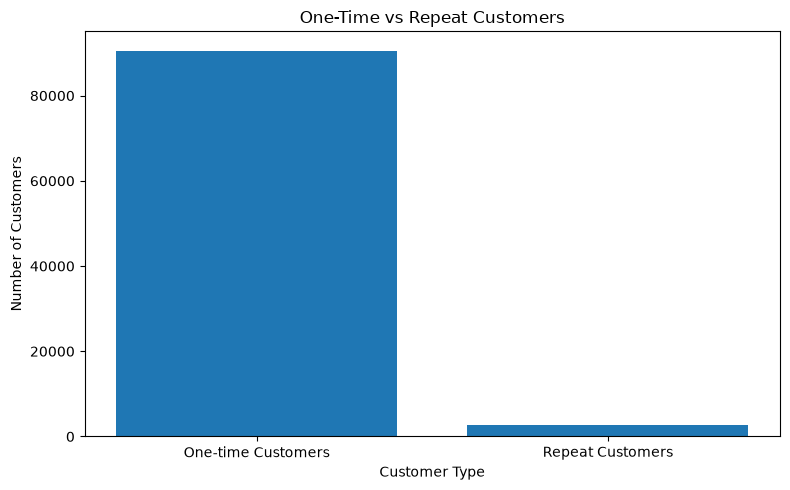

In [350]:
import matplotlib.pyplot as plt

# Calculate one-time customers
one_time_customers = total_customers - repeat_customers

# Prepare the chart
categories = ["One-time Customers", "Repeat Customers"]
values = [one_time_customers, repeat_customers]

# Create bar chart
plt.figure(figsize=(8, 5))

plt.bar(categories, values)

plt.title("One-Time vs Repeat Customers")
plt.xlabel("Customer Type")
plt.ylabel("Number of Customers")

plt.tight_layout()
plt.show()

In [351]:
# Classify customers based on purchase frequency
customer_profile["customer_type"] = (
    customer_profile["number_of_orders"]
    .apply(
        lambda x: "Repeat Customer" if x > 1
        else "One-time Customer"
    )
)

# Calculate average spending for each group
average_spending = (
    customer_profile
    .groupby("customer_type")["total_product_spend"]
    .mean()
)

print(average_spending)

customer_type
One-time Customer    137.958295
Repeat Customer      260.053106
Name: total_product_spend, dtype: float64
